<a href="https://colab.research.google.com/github/jvillagra66-oss/ml-inventario-superstore/blob/main/notebooks/01_analisis_inventario.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 # Proyecto de Ciencia de Datos & Machine Learning: Análisis e Inventario Superstore

### **Descripción del Proyecto**
Este proyecto consiste en el análisis exploratorio y la preparación de datos para un modelo de **Machine Learning**. Utilizando un dataset de **Kaggle** correspondiente a las transacciones de una tienda minorista (*Superstore*), analizaremos el flujo de ventas, el comportamiento de los métodos de pago y el movimiento de stock.

Se aplican buenas prácticas de manipulación, limpieza y estandarización de datos para entrenar un modelo de aprendizaje automático capaz de predecir métricas y eventos clave para la toma de decisiones de negocio.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os # Import the os module

# Download latest version
path = kagglehub.dataset_download("bravehart101/sample-supermarket-dataset")

print("Path to dataset files:", path)

100%|██████████| 164k/164k [00:00<00:00, 16.1MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/bravehart101/sample-supermarket-dataset/versions/1


#Se Crea un DataFram .

In [3]:
df = pd.read_csv(os.path.join(path, "SampleSuperstore.csv"))

display(df)

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,Second Class,Consumer,United States,Miami,Florida,33180,South,Furniture,Furnishings,25.2480,3,0.20,4.1028
9990,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Furniture,Furnishings,91.9600,2,0.00,15.6332
9991,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Technology,Phones,258.5760,2,0.20,19.3932
9992,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Office Supplies,Paper,29.6000,4,0.00,13.3200


#Conteo  las filas y columnas

In [4]:
df.shape

(9994, 13)

#Tipo de datos del dataframe


In [5]:
df.dtypes

,0
Ship Mode,object
Segment,object
Country,object
City,object
State,object
Postal Code,int64
Region,object
Category,object
Sub-Category,object
Sales,float64


#Se calcula cuantos valores nulos tenemos .

In [6]:
df.isnull().sum()

,0
Ship Mode,0
Segment,0
Country,0
City,0
State,0
Postal Code,0
Region,0
Category,0
Sub-Category,0
Sales,0


#Se calcula cuantos valores duplicados tienen el dataframe

In [7]:
df.duplicated().sum()

np.int64(17)

#Se puede ver el tipo de datos duplicado la filas y columnas

In [8]:
# 1. cantidad total de filas identicas duplicados
duplicados_total = df.duplicated().sum()
print(f"filas 100% duplicadas: {duplicados_total}")

# 2. ver una muestra de esas filas duplicadas
df[df.duplicated(keep=False)].head(6)

filas 100% duplicadas: 17


,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
568,Standard Class,Corporate,United States,Seattle,Washington,98105,West,Office Supplies,Paper,19.440,3,0.0,9.3312
591,Standard Class,Consumer,United States,Salem,Oregon,97301,West,Office Supplies,Paper,10.368,2,0.2,3.6288
935,Standard Class,Home Office,United States,Philadelphia,Pennsylvania,19120,East,Office Supplies,Paper,15.552,3,0.2,5.4432
950,Standard Class,Home Office,United States,Philadelphia,Pennsylvania,19120,East,Office Supplies,Paper,15.552,3,0.2,5.4432
1186,Standard Class,Corporate,United States,Seattle,Washington,98103,West,Office Supplies,Paper,25.920,4,0.0,12.4416
1479,Standard Class,Consumer,United States,San Francisco,California,94122,West,Office Supplies,Paper,25.920,4,0.0,12.4416


#Se procede a eliminar los datos duplicados

In [9]:
# Eliminar duplicados

df = df.drop_duplicates()

# Reindexar el Dataframe para que las filas queden continuas
df = df.reset_index(drop=True)

# Confirmar que ya no existe duplicados
print(f"Filas 100% duplicadas restantes: {df.duplicated().sum()}")
print(f"Nuevas dimensiones del dataset: {df.shape}")

Filas 100% duplicadas restantes: 0
Nuevas dimensiones del dataset: (9977, 13)


#Se elimina columnas que no usares en el Datafram

In [10]:
# Eliminamos columnas que no usaremos en el modelo predictivo
columnas_a_eliminar = ["Discount"]
df = df.drop(columns=columnas_a_eliminar)

df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,2.5164


#Se muestan variale categoricas para ir entrenando el modelo

In [11]:
# Detectamos variables categoricas y numericas
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Mostrar los resultados
print(f"Variables categoricas ({len(cat_cols)}):")
print(cat_cols)
print("\nVariables numericas ({len(num_cols)})")
print(num_cols)

Variables categoricas (8):
['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Region', 'Category', 'Sub-Category']

Variables numericas ({len(num_cols)})
['Postal Code', 'Sales', 'Quantity', 'Profit']


#Se realiza una copia del Dataframe y se usa one-hot

In [12]:
# Se realiza una copia de Dataframe
df_temp = df.copy()

# Se aplican one-hot Encoding y guaardamos solo las nuevas columnas
embarked_dummies = pd.get_dummies(df_temp["Ship Mode"], prefix= "Ship Mode", drop_first=False)

display(embarked_dummies)

,Ship Mode_First Class,Ship Mode_Same Day,Ship Mode_Second Class,Ship Mode_Standard Class
0,False,False,True,False
1,False,False,True,False
2,False,False,True,False
3,False,False,False,True
4,False,False,False,True
...,...,...,...,...
9972,False,False,True,False
9973,False,False,False,True
9974,False,False,False,True
9975,False,False,False,True


#Concatenacion del Dataframe

In [13]:
# Concatenamos las nuevas columnas al DataFrame original
df_temp = pd.concat([df_temp, embarked_dummies], axis=1)

# Mostramos las nuevas columnas codificadas
df_temp[['Ship Mode_First Class', 'Ship Mode_Same Day', 'Ship Mode_Second Class', 'Ship Mode_Standard Class']].head()

,Ship Mode_First Class,Ship Mode_Same Day,Ship Mode_Second Class,Ship Mode_Standard Class
0,False,False,True,False
1,False,False,True,False
2,False,False,True,False
3,False,False,False,True
4,False,False,False,True


#Se procede a estandarizar el Datafram

In [14]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

# 1. Instanciar el codificador
ohe = OneHotEncoder(drop='first', sparse_output=False)

# 2. Seleccionar la columna a transformar (por ejemplo, 'Ship Mode')
columna_transformada = ohe.fit_transform(df[['Ship Mode']])

# 3. Crear un DataFrame con las nuevas columnas binarias
df_ohe = pd.DataFrame(columna_transformada, columns=ohe.get_feature_names_out(['Ship Mode']))

# 4. Concatenar de vuelta al DataFrame original
df = pd.concat([df, df_ohe], axis=1)

# Ver las nuevas columnas generadas
df_ohe.head()

,Ship Mode_Same Day,Ship Mode_Second Class,Ship Mode_Standard Class
0,0.0,1.0,0.0
1,0.0,1.0,0.0
2,0.0,1.0,0.0
3,0.0,0.0,1.0
4,0.0,0.0,1.0


#Se aplica el get_dummies

In [15]:
import pandas as pd

# 1.aplicamos get_dummies a una columna categorica
ship_dummies = pd.get_dummies(df["Ship Mode"], prefix="Ship_mode")
# 2. Imprimimos para verificar
print(ship_dummies.head())

# 3.integramos la nueva columna al DataFrame principal
df = pd.concat([df, ship_dummies],axis=1)

   Ship_mode_First Class  Ship_mode_Same Day  Ship_mode_Second Class  \
0                  False               False                    True   
1                  False               False                    True   
2                  False               False                    True   
3                  False               False                   False   
4                  False               False                   False   

   Ship_mode_Standard Class  
0                     False  
1                     False  
2                     False  
3                      True  
4                      True  


#Se Normalizan el dataframe

In [16]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

#1. copias de respaldo
df_model = df.copy()

#2. One-hot Encoding para variables categoricas de superstore
ship_dummies = pd.get_dummies(df_model["Ship Mode"], prefix="Ship_Mode", drop_first=False)
region_dummies = pd.get_dummies(df_model["Region"], prefix="Region", drop_first=False)

#3. Escala MinMax para sales y Profit
scaler = MinMaxScaler()
df_model[["Sales_normalizada", "Profit_normalizada"]] = scaler.fit_transform(df_model[["Sales", "Profit"]])

#4. Definir variables objetivo "y" y columna preditoras "x"
y = df_model["Quantity"]

# Concatenamos los dummies y las columnas normalizadas para crear el conjunto de características 'x'
columnas_feature = [
    "Sales_normalizada",
    "Profit_normalizada"
]

x = pd.concat([df_model[columnas_feature], ship_dummies, region_dummies], axis=1)

# Mostrar las primeras filas de x
x.head()

,Sales_normalizada,Profit_normalizada,Ship_Mode_First Class,Ship_Mode_Same Day,Ship_Mode_Second Class,Ship_Mode_Standard Class,Region_Central,Region_East,Region_South,Region_West
0,0.011552,0.442794,False,False,True,False,False,False,True,False
1,0.032313,0.454639,False,False,True,False,False,False,True,False
2,0.000626,0.440458,False,False,True,False,False,False,False,True
3,0.042280,0.414464,False,False,False,True,False,False,True,False
4,0.000968,0.440168,False,False,False,True,False,False,True,False


#Combinamos x e y para eliminar filas con valores faltantes si los hubiera

In [17]:

df_modelo_clean = pd.concat([x, y], axis=1).dropna()

# Separamos nuevamente X e y
y = df_modelo_clean['Quantity']
X = df_modelo_clean[columnas_feature]

# Verificamos que no queden valores faltantes
print("¿Hay NaN en X?:", x.isna().sum().sum() > 0)
print("¿Hay NaN en y?:", y.isna().sum().sum() > 0)

¿Hay NaN en X?: False
¿Hay NaN en y?: False


#Dividimos los datos: 80% entrenamiento y 20% prueba

In [18]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Verificamos las dimensiones finales
print(f"Datos de entrenamiento:{x_train.shape}")
print(f"Datos de prueba {x_test.shape}")

Datos de entrenamiento:(7981, 10)
Datos de prueba (1996, 10)


#Se Crean variables para el modelo

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Creamos la variable objetivo binaria "Stockout_Risk" para la prediccion de quiebre
df_model["Stockout_Risk"] = (df_model["Quantity"] > 3).astype(int)

# 2. Definimos x (caracteristicas) e y (objetivo)
# Usamos la variable 'x' que ya fue correctamente definida y estructurada en la celda anterior
y = df_model["Stockout_Risk"]

# 3. Dividimos en Train y Test (80% / 20%)
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# 4. Creamos y entrenamos el modelo de Regresion logistica
modelo_surf = LogisticRegression()
modelo_surf.fit(x_train, y_train)

# 5. Mostrar Coeficientes
coef_df = pd.DataFrame({"variable": x.columns, "coeficiente": modelo_surf.coef_[0]})
display(coef_df)

,variable,coeficiente
0,Sales_normalizada,9.074553
1,Profit_normalizada,1.286493
2,Ship_Mode_First Class,-0.099682
3,Ship_Mode_Same Day,-0.284424
4,Ship_Mode_Second Class,-0.100017
5,Ship_Mode_Standard Class,-0.091318
6,Region_Central,-0.131431
7,Region_East,-0.184932
8,Region_South,-0.128984
9,Region_West,-0.130095


#Se crean Matriz de confusio para ver datos como el acuracy

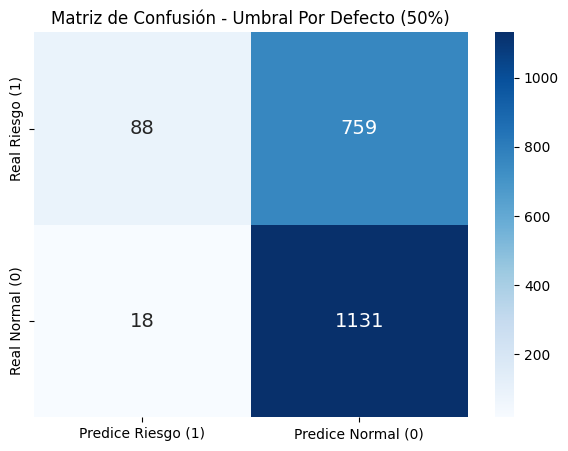

                     precision    recall  f1-score   support

Riesgo Stockout (1)       0.83      0.10      0.18       847
         Normal (0)       0.60      0.98      0.74      1149

           accuracy                           0.61      1996
          macro avg       0.71      0.54      0.46      1996
       weighted avg       0.70      0.61      0.51      1996



In [20]:
# Realizar predicciones con el umbral por defecto (0.50)
y_pred = modelo_surf.predict(x_test)

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred, labels=[1, 0])

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', annot_kws={"size": 14},
            xticklabels=['Predice Riesgo (1)', 'Predice Normal (0)'],
            yticklabels=['Real Riesgo (1)', 'Real Normal (0)'])
plt.title("Matriz de Confusión - Umbral Por Defecto (50%)")
plt.show()

# Reporte de métricas
print(classification_report(y_test, y_pred, labels=[1, 0], target_names=['Riesgo Stockout (1)', 'Normal (0)']))

#Se crean nueva matriz umbral  para ver datos como el acuracy

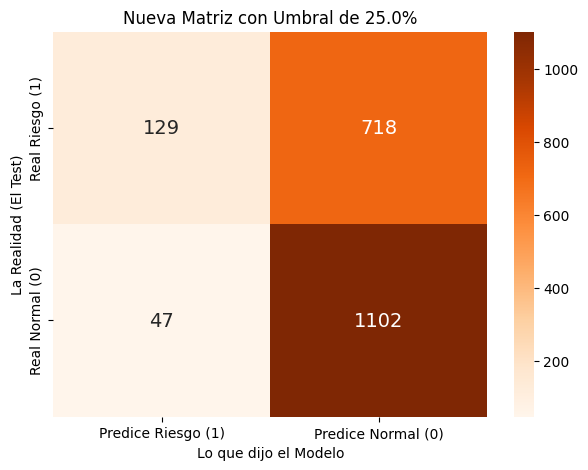

                     precision    recall  f1-score   support

Riesgo Stockout (1)       0.73      0.15      0.25       847
         Normal (0)       0.61      0.96      0.74      1149

           accuracy                           0.62      1996
          macro avg       0.67      0.56      0.50      1996
       weighted avg       0.66      0.62      0.53      1996



In [21]:
# 1. Obtener las probabilidades predichas
probabilidades = modelo_surf.predict_proba(x_test)[:, 1]

# 2. Definir nuevo umbral más sensible (40%)
nuevo_umbral = 0.47
y_pred_sensible = (probabilidades >= nuevo_umbral).astype(int)

# 3. Nueva Matriz de Confusión (Color Naranja)
cm_sensible = confusion_matrix(y_test, y_pred_sensible, labels=[1, 0])

plt.figure(figsize=(7, 5))
sns.heatmap(cm_sensible, annot=True, fmt='d', cmap='Oranges', annot_kws={"size": 14},
            xticklabels=['Predice Riesgo (1)', 'Predice Normal (0)'],
            yticklabels=['Real Riesgo (1)', 'Real Normal (0)'])
plt.title("Nueva Matriz con Umbral de 25.0%")
plt.xlabel("Lo que dijo el Modelo")
plt.ylabel("La Realidad (El Test)")
plt.show()

# 4. Reporte final actualizado
print(classification_report(y_test, y_pred_sensible, labels=[1, 0], target_names=['Riesgo Stockout (1)', 'Normal (0)']))

#Regresion lineal

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
import ipywidgets as widgets

# 1. Tomamos una muestra de datos reales de tu proyecto (ej. 50 transacciones)
# Para evaluar la relación entre Ventas (X) y Ganancias (Y)
muestra = df[['Sales', 'Profit']].dropna().sample(n=50, random_state=42)

x_reales = muestra['Sales'].values
y_reales = muestra['Profit'].values

# 2. Definimos la función del simulador interactivo
def simulador_lineal(a, b):
    # Generamos valores de X para trazar la línea continua
    x_recta = np.linspace(x_reales.min(), x_reales.max(), 100)
    y_recta = a * x_recta + b

    # Calculamos la predicción para los puntos reales
    predicciones = a * x_reales + b

    # Calculamos el Error Cuadrático Medio (MSE)
    mse = np.mean((y_reales - predicciones) ** 2)

    # Configuración de la figura
    plt.figure(figsize=(10, 5))

    # Dibujamos los puntos reales de tu dataset (Ventas vs Ganancias)
    plt.scatter(x_reales, y_reales, color='red', s=40, zorder=4, label='Datos Reales (Superstore)')

    # Dibujamos la recta de predicción
    plt.plot(x_recta, y_recta, color='blue', linewidth=2, label=f'Fórmula: y = {a:.2f}x + {b:.2f}')

    # Líneas de error (residuos) entre cada punto real y la recta
    for xr, yr, pred in zip(x_reales, y_reales, predicciones):
        plt.plot([xr, xr], [yr, pred], color='gray', linestyle=':', alpha=0.6)

    # Detalles visuales del gráfico
    plt.title(f'Simulador de Regresión Lineal - Superstore\nError Cuadrático Medio (MSE): {mse:.2f}', fontsize=12, fontweight='bold')
    plt.xlabel('Ventas / Sales ($)', fontsize=10)
    plt.ylabel('Ganancia / Profit ($)', fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(fontsize=10)
    plt.show()

# 3. Creamos los deslizadores interactivos (ajustados a la escala de tu proyecto)
interact(simulador_lineal,
    a=widgets.FloatSlider(value=0.1, min=-1.0, max=1.0, step=0.01, description='a (Pendiente)'),
    b=widgets.FloatSlider(value=0.0, min=-100.0, max=100.0, step=1.0, description='b (Sesgo/Intercepto)')
);

interactive(children=(FloatSlider(value=0.1, description='a (Pendiente)', max=1.0, min=-1.0, step=0.01), Float…

# 1. Carga y Exploración de Datos (EDA)

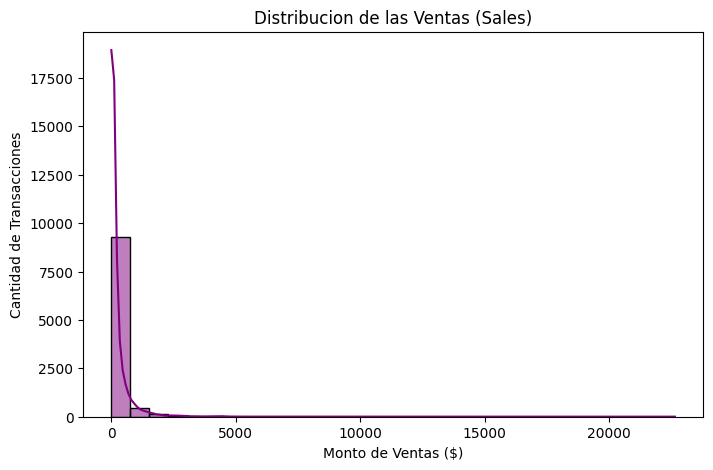

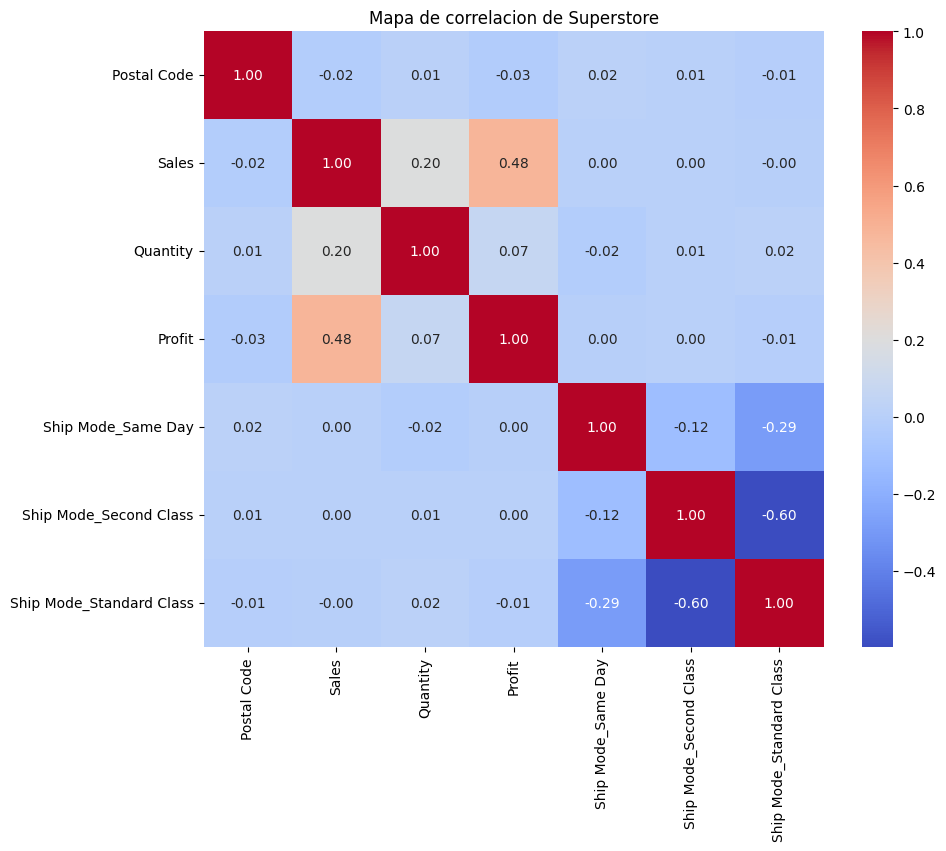

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Visualizacion 1 : Distribucion de las ventas (Sales)

plt.figure(figsize=(8, 5))
sns.histplot(df["Sales"], bins=30, kde=True, color="purple")
plt.title("Distribucion de las Ventas (Sales)")
plt.xlabel("Monto de Ventas ($)")
plt.ylabel("Cantidad de Transacciones")
plt.show()

# Visualizacion 2 : Analisis de correlancion entre las variuables

plt.figure(figsize=(10, 8))

#seleccionamos solo las columnas numericas para el mapa de calor
Columnas_numericas = df.select_dtypes(include=[np.number])

# Graficamos el mapa de calor de la correlaciones
sns.heatmap(Columnas_numericas.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Mapa de correlacion de Superstore")
plt.show()

# 2. Preprocesamiento de Datos

In [24]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# Hacemos una copia limpia del DataFrame original
df_limpio = df.copy()

# 1. Creación de la variable objetivo binaria: Riesgo de Quiebre de Stock
# (1 si la cantidad demandada es alta > 3, 0 de lo contrario)
df_limpio['Stockout_Risk'] = (df_limpio['Quantity'] > 3).astype(int)

# 2. Escalado de variables numéricas financieras
# Usamos MinMaxScaler para llevar Sales y Profit a un rango entre 0 y 1
scaler = MinMaxScaler()
df_limpio[['Sales', 'Profit']] = scaler.fit_transform(df_limpio[['Sales', 'Profit']])

# 3. Codificación One-Hot de variables categóricas clave (ej. Ship Mode, Region)
df_limpio = pd.get_dummies(df_limpio, columns=['Ship Mode', 'Region', 'Category'], drop_first=True)

# 4. Eliminación de variables innecesarias o identificadores que no sirven para predecir
columnas_a_borrar = [
    'Row ID', 'Order ID', 'Order Date', 'Ship Date',
    'Customer ID', 'Customer Name', 'Segment', 'Country',
    'City', 'State', 'Postal Code', 'Product ID',
    'Sub-Category', 'Product Name', 'Quantity'
]

df_limpio = df_limpio.drop(columns=columnas_a_borrar, errors='ignore')

# Visualizamos las primeras filas del dataset listo
display(df_limpio.head())

,Sales,Profit,Ship Mode_Same Day,Ship Mode_Second Class,Ship Mode_Standard Class,Ship_mode_First Class,Ship_mode_Same Day,Ship_mode_Second Class,Ship_mode_Standard Class,Stockout_Risk,Ship Mode_Same Day,Ship Mode_Second Class,Ship Mode_Standard Class,Region_East,Region_South,Region_West,Category_Office Supplies,Category_Technology
0,0.011552,0.442794,0.0,1.0,0.0,False,False,True,False,0,False,True,False,False,True,False,False,False
1,0.032313,0.454639,0.0,1.0,0.0,False,False,True,False,0,False,True,False,False,True,False,False,False
2,0.000626,0.440458,0.0,1.0,0.0,False,False,True,False,0,False,True,False,False,False,True,True,False
3,0.042280,0.414464,0.0,0.0,1.0,False,False,False,True,1,False,False,True,False,True,False,False,False
4,0.000968,0.440168,0.0,0.0,1.0,False,False,False,True,0,False,False,True,False,True,False,True,False


In [25]:
# 5. Selección de variables relevantes
# Separamos nuestras características (X) de nuestro objetivo a predecir (y)
X = df_limpio.drop(columns=['Stockout_Risk'])
y = df_limpio['Stockout_Risk']

# División del dataset en conjuntos de entrenamiento y prueba
# Usamos un 80% para entrenar y un 20% para la prueba final (test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Tendremos {X_train.shape[0]} registros para entrenar el modelo.")
print(f"Y {X_test.shape[0]} registros guardados para evaluar su rendimiento final.")

Tendremos 7981 registros para entrenar el modelo.
Y 1996 registros guardados para evaluar su rendimiento final.


# 3. Modelado (KNN / Regresión)

In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import pandas as pd

# Definimos la variable continua a predecir (y = Sales o Profit)
y = df_model["Sales"]

#2. Definimos las caracteristicas explicativas (x)
# Incluimos variables numericas y las dummified de Ship Mode o Region
columnas_x = ["Quantity", "Profit"] + [col for col in df_model.columns if col.startswith(("Ship_Mode", "Region"))]

#3. Dividimos en conjuntos de Entrenamiento (Train) y Prueba (Test)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

#4.  Creamos y entrenamos el modelo de Regresion Lineal
model_lin = LinearRegression()
model_lin.fit(x_train, y_train)

#5. Estraemos el intercepto y coeficientes de un Dataframe
coeficientes = pd.DataFrame({
    "Variable": x_train.columns,
    "Coeficiente": model_lin.coef_
})

print("Intercepto", model_lin.intercept_)
print(coeficientes)

Intercepto 0.4440000000002442
                   Variable   Coeficiente
0         Sales_normalizada  2.263804e+04
1        Profit_normalizada -5.022975e-13
2     Ship_Mode_First Class  3.219717e-14
3        Ship_Mode_Same Day -1.041252e-14
4    Ship_Mode_Second Class -1.334722e-13
5  Ship_Mode_Standard Class  1.116876e-13
6            Region_Central -7.822789e-14
7               Region_East  7.217586e-13
8              Region_South -7.252367e-15
9               Region_West -6.362784e-13


In [27]:
from sklearn.metrics import mean_absolute_error

# Usa 'model_lin' que es el nombre del modelo entrenado anteriormente
y_pred = model_lin.predict(x_test)

# Calculamos el error absoluto medio (MAE)
mae = mean_absolute_error(y_test, y_pred)

print(f"Mean Absolute error (MAE): {mae:.2f}")

Mean Absolute error (MAE): 0.00


In [28]:
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

try:
    # 1. Aseguramos una copia fresca y limpia de df_model para evitar conflictos de estado
    df_eval = df_model.copy()

    # 2. Recreamos localmente las columnas escaladas si no existen
    if "Sales_normalizada" not in df_eval.columns or "Profit_normalizada" not in df_eval.columns:
        temp_scaler = MinMaxScaler()
        df_eval[["Sales_normalizada", "Profit_normalizada"]] = temp_scaler.fit_transform(df_eval[["Sales", "Profit"]])

    # 3. Reconstruimos la matriz de variables dummy de forma idéntica al entrenamiento
    ship_dummies = pd.get_dummies(df_eval["Ship Mode"], prefix="Ship_Mode", drop_first=False)
    region_dummies = pd.get_dummies(df_eval["Region"], prefix="Region", drop_first=False)

    # Concatenamos de forma segura las características
    x_original_reg = pd.concat([df_eval[["Sales_normalizada", "Profit_normalizada"]], ship_dummies, region_dummies], axis=1)
    y_original_reg = df_eval["Sales"]

    # 4. Volvemos a hacer la separación (test_size=0.2, random_state=42)
    _, x_test_reg, _, y_test_reg = train_test_split(x_original_reg, y_original_reg, test_size=0.2, random_state=42)

    # 5. Realizamos las predicciones
    y_pred_reg = model_lin.predict(x_test_reg)

    # 6. Calculamos el Error Cuadrático Medio
    mse = mean_squared_error(y_test_reg, y_pred_reg)
    print(f"Mean Squared Error (MSE): {mse:.4e}")
except Exception as e:
    print(f"Ocurrió un error al evaluar el modelo: {e}")

Mean Squared Error (MSE): 2.9829e-25


In [29]:
from sklearn.metrics import r2_score

# R2 Score calculation
r2 = r2_score(y_test, y_pred)
print(f"R2: {r2:.2f}")

R2: 1.00


# 5. Simulador Interactivo

In [30]:
import ipywidgets as widgets
from ipywidgets import interact
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Redefinimos localmente la partición usando las columnas originales 'Sales' y 'Profit' para el simulador
x_knn = df_model[['Sales', 'Profit']]
y_knn = df_model["Stockout_Risk"]
x_train_knn_raw, x_test_knn_raw, y_train_knn, y_test_knn = train_test_split(x_knn, y_knn, test_size=0.2, random_state=42)

# Aseguramos de entrenar un escalador y modelo KNN con las variables correctas de Stockout_Risk (0 y 1)
scaler_knn = StandardScaler()
x_train_escalado_knn = scaler_knn.fit_transform(x_train_knn_raw)

def simulador_knn_stock(ventas, ganancia, k_vecinos):
    # 1. Instanciamos el clasificador KNN con el número de vecinos seleccionado
    knn_temp = KNeighborsClassifier(n_neighbors=k_vecinos)
    knn_temp.fit(x_train_escalado_knn, y_train_knn)

    # 2. Preparamos y escalamos el nuevo punto de consulta como DataFrame para evitar warnings
    punto_nuevo = pd.DataFrame([[ventas, ganancia]], columns=['Sales', 'Profit'])
    punto_nuevo_escalado = scaler_knn.transform(punto_nuevo)

    # 3. Predicción y probabilidades
    prediccion = knn_temp.predict(punto_nuevo_escalado)[0]
    probabilidades = knn_temp.predict_proba(punto_nuevo_escalado)[0]

    # 4. Buscamos los vecinos más cercanos en el espacio escalado
    distancias, indices = knn_temp.kneighbors(punto_nuevo_escalado)
    vecinos_x = x_train_escalado_knn[indices[0]]

    # 5. Graficamos el espacio bidimensional escalado
    plt.figure(figsize=(9, 6))

    # Datos de entrenamiento usando los arrays binarios correctos
    plt.scatter(x_train_escalado_knn[y_train_knn == 0, 0], x_train_escalado_knn[y_train_knn == 0, 1],
                color='blue', alpha=0.4, label='Normal (0)', edgecolors='black', s=20)
    plt.scatter(x_train_escalado_knn[y_train_knn == 1, 0], x_train_escalado_knn[y_train_knn == 1, 1],
                color='darkorange', alpha=0.4, label='Riesgo Stockout (1)', edgecolors='black', s=20)

    # Punto simulado
    color_punto = 'darkorange' if prediccion == 1 else 'blue'
    plt.scatter(punto_nuevo_escalado[0, 0], punto_nuevo_escalado[0, 1],
                color=color_punto, marker='*', s=300, label='Producto Simulado', edgecolors='black', zorder=5)

    # Dibujamos líneas hacia los K vecinos más cercanos
    for idx in range(k_vecinos):
        vecino_pt = vecinos_x[idx]
        plt.plot([punto_nuevo_escalado[0, 0], vecino_pt[0]],
                 [punto_nuevo_escalado[0, 1], vecino_pt[1]],
                 color='red', linestyle='--', linewidth=1.5, alpha=0.8)

    resultado_texto = "RIESGO DE STOCKOUT (1)" if prediccion == 1 else "STOCK NORMAL (0)"
    confianza = probabilidades[prediccion] * 100

    plt.title(f"Simulador KNN (K = {k_vecinos}) | Predicción: {resultado_texto} ({confianza:.0f}% de votos)", fontsize=12, fontweight='bold')
    plt.xlabel('Ventas Escaladas (Sales)')
    plt.ylabel('Ganancia Escalada (Profit)')
    plt.legend(loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()

# Controles interactivos con sliders
interact(simulador_knn_stock,
         ventas=widgets.FloatSlider(value=500, min=0, max=5000, step=50, description='Ventas ($):'),
         ganancia=widgets.FloatSlider(value=100, min=-500, max=2000, step=20, description='Profit ($):'),
         k_vecinos=widgets.IntSlider(value=5, min=1, max=15, step=2, description='Vecinos (K):'));

interactive(children=(FloatSlider(value=500.0, description='Ventas ($):', max=5000.0, step=50.0), FloatSlider(…


# 4. Evaluación del Modelo classification_report.

Accuracy Global: 0.66


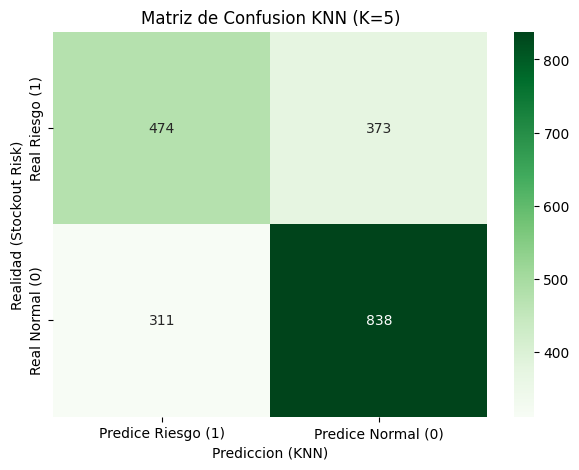


Reporte de Clasificacion:
              precision    recall  f1-score   support

  Normal (0)       0.69      0.73      0.71      1149
  Riesgo (1)       0.60      0.56      0.58       847

    accuracy                           0.66      1996
   macro avg       0.65      0.64      0.65      1996
weighted avg       0.65      0.66      0.66      1996



In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Ensure df is defined
try:
    df_model = df.copy()
except NameError:
    # Reload df using the path defined earlier in the notebook
    try:
        df = pd.read_csv(os.path.join(path, "SampleSuperstore.csv"))
        df_model = df.copy()
    except NameError:
        print("Error: The dataset path is not defined. Please run the cell that downloads the dataset first.")

# 1. Copia limpia y creacion de variables objetivo (Riesgo si Quantity > 3)
df_model["Stockout_Risk"] = (df_model["Quantity"] > 3).astype(int)

# 2. Selecion de columnas continua para KNN (Sales y Profit)
columnas_x = ["Sales", "Profit"]

x = df_model[columnas_x]
y = df_model["Stockout_Risk"]

# 3. Division Train/Test (80% / 20%)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# 4. Escalando de variables con StandardScaler
scaler = StandardScaler()
x_train_escalado = scaler.fit_transform(x_train)
x_test_escalado = scaler.transform(x_test)

# 5. Entrenamiento del modelo KNN (K=5 vecinos)
cantidad_vecinos = 5
modelo_knn = KNeighborsClassifier(n_neighbors=cantidad_vecinos)
modelo_knn.fit(x_train_escalado, y_train)

# 6. Prediccion en Test
y_pred = modelo_knn.predict(x_test_escalado)

# 7. Metricas y Matriz de confusion
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy Global: {acc:.2f}")

cm = confusion_matrix(y_test, y_pred, labels=[1, 0])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Predice Riesgo (1)", "Predice Normal (0)"],
    yticklabels=["Real Riesgo (1)", "Real Normal (0)"]
)
plt.title(f"Matriz de Confusion KNN (K={cantidad_vecinos})")
plt.xlabel("Prediccion (KNN)")
plt.ylabel("Realidad (Stockout Risk)")
plt.show()

print("\nReporte de Clasificacion:")
print(classification_report(y_test, y_pred, target_names=["Normal (0)", "Riesgo (1)"]))

# 6. Seccion Arboles de decision y control de sobreajuste (OVERFITTING)


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# 7. Preparacion del DataFrame para el arbol


In [33]:
df_arbol = df.copy()

# Definimos la variable oobjetivo binario (1 si Quantity >3, de lo contrario 0)

In [34]:
df_arbol["Stockout_Risk"] = (df_arbol['Quantity'] > 3).astype(int)

#8 Seleccionamos las características explicativas (Sales, Profit y categóricas codificadas)
# Los árboles no requieren escalado (MinMaxScaler/StandardScaler)
# y División Train / Test con estratificación para mantener la proporción

In [35]:
df_arbol = pd.get_dummies(df_arbol, columns=['Ship Mode', 'Region', 'Category'], drop_first=True)

columnas_x = [col for col in df_arbol.columns if col not in [
    'Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Customer ID',
    'Customer Name', 'Segment', 'Country', 'City', 'State',
    'Postal Code', 'Product ID', 'Sub-Category', 'Product Name',
    'Quantity', 'Stockout_Risk'
]]

X = df_arbol[columnas_x]
y = df_arbol['Stockout_Risk']

# 2. División Train / Test con estratificación para mantener la proporción
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Registros de Entrenamiento: {X_train.shape[0]} | Registros de Prueba: {X_test.shape[0]}")

Registros de Entrenamiento: 7981 | Registros de Prueba: 1996


# 9. ÁRBOL PODADO (max_depth=3) - Control de Sobreajuste e Interpretabilidad


=== ÁRBOL PODADO (max_depth=3) ===
Exactitud en TRAIN: 0.651
Exactitud en TEST : 0.651


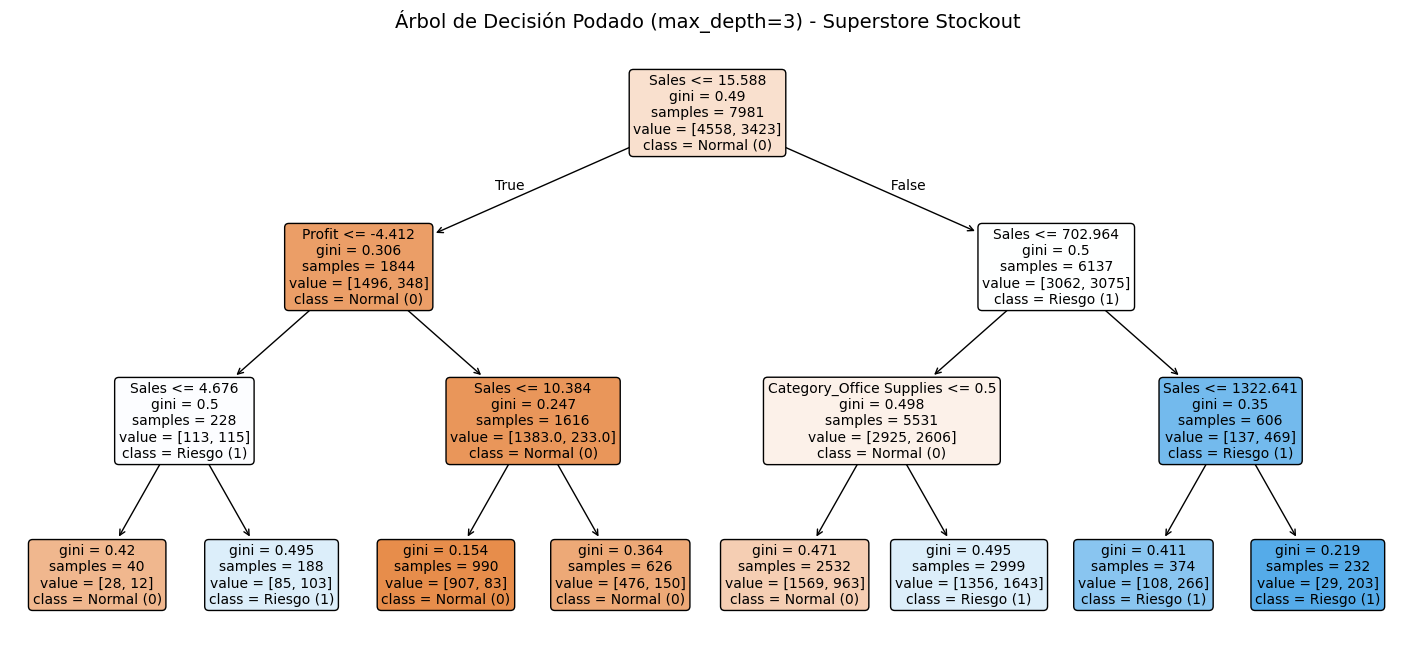

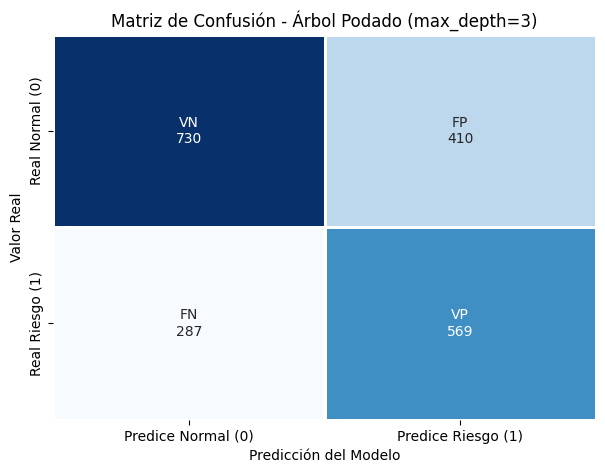

Reporte de Clasificación (Árbol Podado):

              precision    recall  f1-score   support

  Normal (0)       0.72      0.64      0.68      1140
  Riesgo (1)       0.58      0.66      0.62       856

    accuracy                           0.65      1996
   macro avg       0.65      0.65      0.65      1996
weighted avg       0.66      0.65      0.65      1996



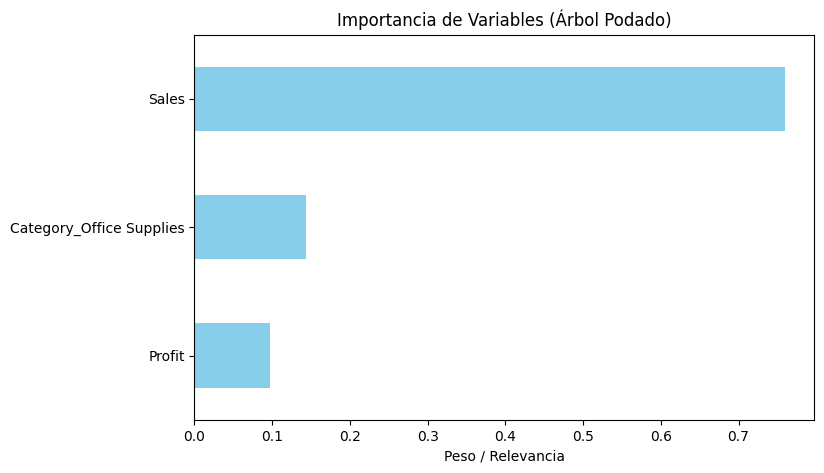

In [36]:
arbol_podado = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol_podado.fit(X_train, y_train)

print("\n=== ÁRBOL PODADO (max_depth=3) ===")
print(f"Exactitud en TRAIN: {arbol_podado.score(X_train, y_train):.3f}")
print(f"Exactitud en TEST : {arbol_podado.score(X_test, y_test):.3f}")

# Visualización del gráfico del árbol
plt.figure(figsize=(18, 8))
plot_tree(
    arbol_podado,
    feature_names=X.columns,
    class_names=["Normal (0)", "Riesgo (1)"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árbol de Decisión Podado (max_depth=3) - Superstore Stockout", fontsize=14)
plt.show()

# Matriz de Confusión Etiquetada para Árbol Podado
y_pred_podado = arbol_podado.predict(X_test)
cm_podado = confusion_matrix(y_test, y_pred_podado, labels=[0, 1])

nombres = np.array([["VN", "FP"], ["FN", "VP"]])
anot = np.array([[f"{nom}\n{val}" for nom, val in zip(fila_n, fila_v)] for fila_n, fila_v in zip(nombres, cm_podado)])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_podado, annot=anot, fmt="", cmap="Blues", cbar=False, linewidths=1, linecolor="white",
    xticklabels=["Predice Normal (0)", "Predice Riesgo (1)"],
    yticklabels=["Real Normal (0)", "Real Riesgo (1)"]
)
plt.title("Matriz de Confusión - Árbol Podado (max_depth=3)", fontsize=12)
plt.xlabel("Predicción del Modelo")
plt.ylabel("Valor Real")
plt.show()

print("Reporte de Clasificación (Árbol Podado):\n")
print(classification_report(y_test, y_pred_podado, target_names=["Normal (0)", "Riesgo (1)"]))

# Importancia de Variables en el Árbol Podado
imp = pd.Series(arbol_podado.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(8, 5))
imp[imp > 0].plot(kind="barh", color="skyblue")
plt.title("Importancia de Variables (Árbol Podado)")
plt.xlabel("Peso / Relevancia")
plt.show()

# 10. ÁRBOL COMPLETO (Sin Podar) - Demostración de Overfitting


=== ÁRBOL SIN PODAR (Sin Límite de Profundidad) ===
Exactitud en TRAIN: 1.000 <- (Memorización / Overfitting)
Exactitud en TEST : 0.696


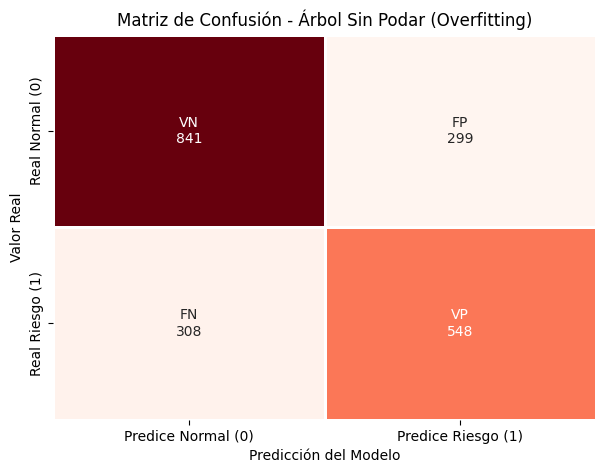


Comparación de Exactitud en TEST: Podado (0.651) vs Sin Podar (0.696)


In [37]:
arbol_completo = DecisionTreeClassifier(random_state=42)
arbol_completo.fit(X_train, y_train)

print("\n=== ÁRBOL SIN PODAR (Sin Límite de Profundidad) ===")
print(f"Exactitud en TRAIN: {arbol_completo.score(X_train, y_train):.3f} <- (Memorización / Overfitting)")
print(f"Exactitud en TEST : {arbol_completo.score(X_test, y_test):.3f}")

y_pred_completo = arbol_completo.predict(X_test)
cm_completo = confusion_matrix(y_test, y_pred_completo, labels=[0, 1])

anot2 = np.array([[f"{nom}\n{val}" for nom, val in zip(fila_n, fila_v)] for fila_n, fila_v in zip(nombres, cm_completo)])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_completo, annot=anot2, fmt="", cmap="Reds", cbar=False, linewidths=1, linecolor="white",
    xticklabels=["Predice Normal (0)", "Predice Riesgo (1)"],
    yticklabels=["Real Normal (0)", "Real Riesgo (1)"]
)
plt.title("Matriz de Confusión - Árbol Sin Podar (Overfitting)", fontsize=12)
plt.xlabel("Predicción del Modelo")
plt.ylabel("Valor Real")
plt.show()

print(f"\nComparación de Exactitud en TEST: Podado ({arbol_podado.score(X_test, y_test):.3f}) vs Sin Podar ({arbol_completo.score(X_test, y_test):.3f})")

# 11 Arbol de decision multiclase (3 categorias)

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix

# Preparamos del Dataset (3 clases : furniture, office supplies, technology)
df_tree = df.copy()

# Variables predictoras
feats = ['Sales', 'Profit']
x = df_tree[feats]
y = df_tree['Category']  # Las 3 clases objetivas

# Verificacion de clases
labels = sorted(y.unique().tolist())
print('Categoria a predecir:', labels)

# Divicion Train/Test
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)



Categoria a predecir: ['Furniture', 'Office Supplies', 'Technology']


# 12 Entrenamiento del arbol de decisiones (max_depth=3)

Exactitud TRAIN: 0.654555
Exactitud TEST : 0.652


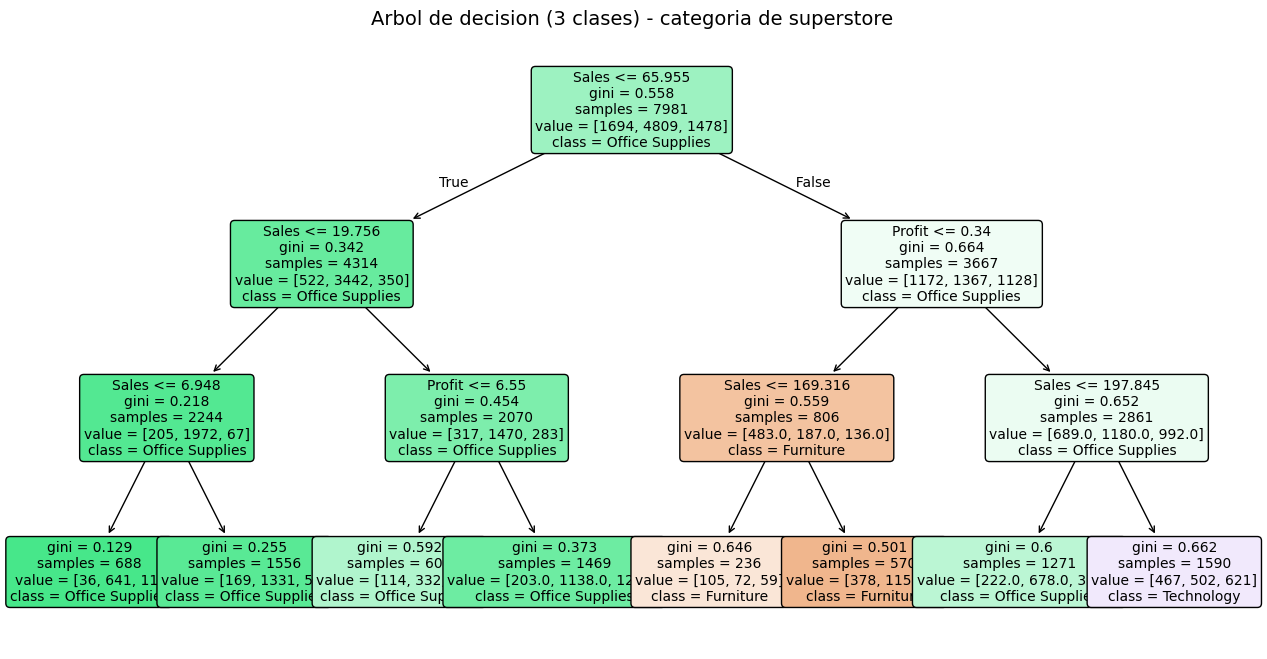

In [39]:
arbol_superstore = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol_superstore.fit(x_train, y_train)

print(f'Exactitud TRAIN: {arbol_superstore.score(x_train, y_train):3f}')
print(f'Exactitud TEST : {arbol_superstore.score(x_test, y_test):.3f}')

# Visualizacion del arbol de decision multiplclase
plt.figure(figsize=(16, 8))
plot_tree(
    arbol_superstore,
    feature_names=feats,
    class_names=labels,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Arbol de decision (3 clases) - categoria de superstore', fontsize=14)
plt.show()

# 13 Matriz de confusion 3x3 Etiquetada (Acierto vs Errores)

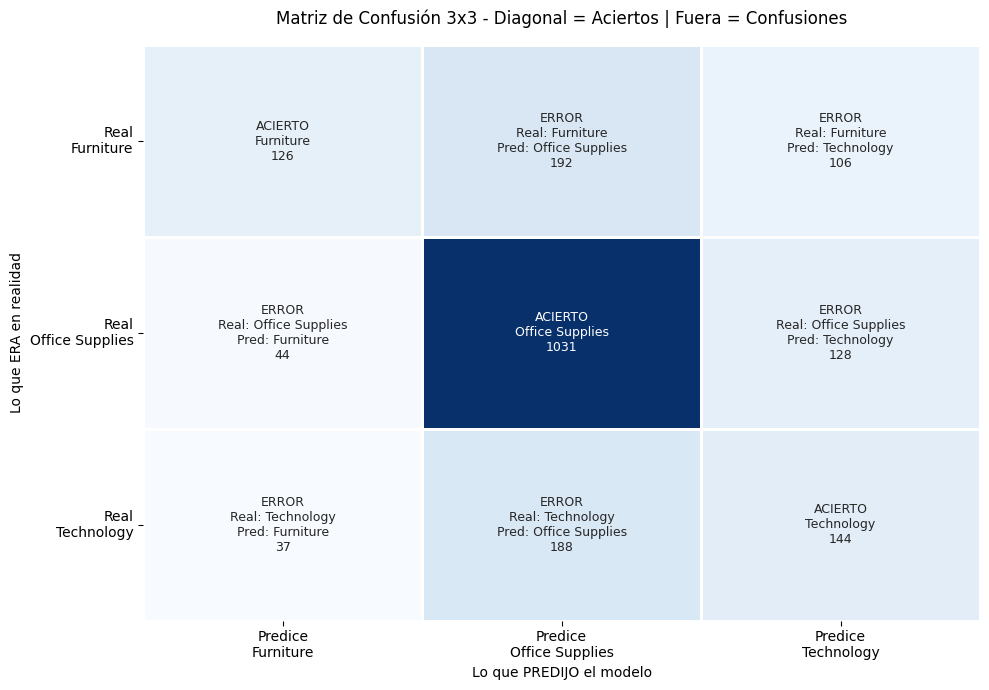

In [40]:
cm = confusion_matrix(y_test, arbol_superstore.predict(x_test), labels=labels)

anot = []
for i, real in enumerate(labels):
    fila = []
    for j, pred in enumerate(labels):
        v = cm[i, j]
        if i == j:
            fila.append(f"ACIERTO\n{real}\n{v}")
        else:
            fila.append(f"ERROR\nReal: {real}\nPred: {pred}\n{v}")
    anot.append(fila)
anot = np.array(anot)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm, annot=anot, fmt="", cmap="Blues", cbar=False,
    linewidths=1, linecolor="white", annot_kws={"size": 9}
)

plt.xticks([0.5, 1.5, 2.5], [f"Predice\n{l}" for l in labels], fontsize=10)
plt.yticks([0.5, 1.5, 2.5], [f"Real\n{l}" for l in labels], rotation=0, fontsize=10)

plt.title("Matriz de Confusión 3x3 - Diagonal = Aciertos | Fuera = Confusiones", fontsize=12, pad=15)
plt.xlabel("Lo que PREDIJO el modelo")
plt.ylabel("Lo que ERA en realidad")
plt.tight_layout()
plt.show()

# 14. Carga de librerias y preparacion de datos

## . Preparación de Datos para Random Forest
Definimos la variable objetivo `Stockout_Risk` (1 si `Quantity > 3`, de lo contrario 0) y aplicamos la codificación de variables categóricas. Separamamos las características ($X$) y la etiqueta ($y$) para luego dividir en entrenamiento ($80\%$) y prueba ($20\%$).

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

sns.set_theme(style='whitegrid', palette= 'pastel')
plt.rcParams['figure.figsize'] = (8, 5)

#1. Copia y definicon de la variabl objetivo
df_rf = df.copy()
df_rf['Stockout_Risk'] = (df_rf['Quantity'] > 3).astype(int)

#2. Codificacion de categoricas
df_rf = pd.get_dummies(df_rf, columns=['Ship Mode', 'Region', 'Category'], drop_first=True)

#3. Selecio de columnas predictoras
columnas_excluir = [
    'Row ID', 'Order ID', 'Orde Date', 'Ship Date', 'Customer ID',
    'Custome Name', 'Segment', 'Country', 'City', 'State',
    'Postal Code', 'Product ID', 'Sub-Category', 'Product Name',
    'Quantity', 'Stockout_Risk'
]
columnas_x = [col for col in df_rf.columns if col not in columnas_excluir]

x = df_rf[columnas_x]
y = df_rf['Stockout_Risk']

#4. Division Train/Test con estratificacion
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Registros de entrenamioent: {x_train.shape[0]} | Registros de prueba: {x_test.shape[0]}')

Registros de entrenamioent: 7981 | Registros de prueba: 1996


# 15. Entrenando el Bosque Aleatorio e Inspección del Modelo
Entrenamos un Árbol de Decisión simple y un Bosque Aleatorio de 100 árboles (`RandomForestClassifier`). Inspeccionamos la estructura interna de uno de los árboles del ensamble.

Arbol Unico -> Train: 0.651 | Test: 0.651
Bosque (100) -> Train: 1.000 | Test: 0.665


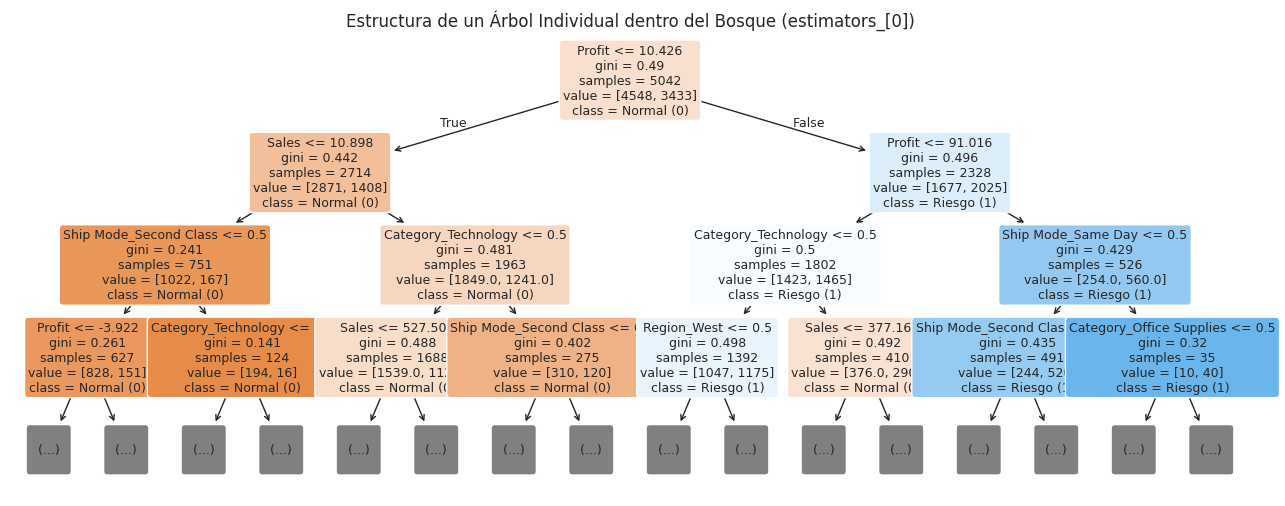

In [42]:
# Entrenamiento de modelos
arbol = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol.fit(x_train, y_train)

modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_rf.fit(x_train, y_train)

print(f'Arbol Unico -> Train: {arbol.score(x_train, y_train):.3f} | Test: {arbol.score(x_test, y_test):.3f}')
print(f'Bosque (100) -> Train: {modelo_rf.score(x_train, y_train):.3f} | Test: {modelo_rf.score(x_test, y_test):.3f}')

# Visualizacion de un arbol del bosque (estimators_[0])
plt.figure(figsize=(16, 6))
plot_tree(
    modelo_rf.estimators_[0],
    feature_names=x_train.columns.tolist(),
    class_names=['Normal (0)', 'Riesgo (1)'],
    filled=True, rounded=True, fontsize=9, max_depth=3
)
plt.title('Estructura de un Árbol Individual dentro del Bosque (estimators_[0])', fontsize=12)
plt.show()

#Análisis de Estabilización (n_estimators) y Evaluación

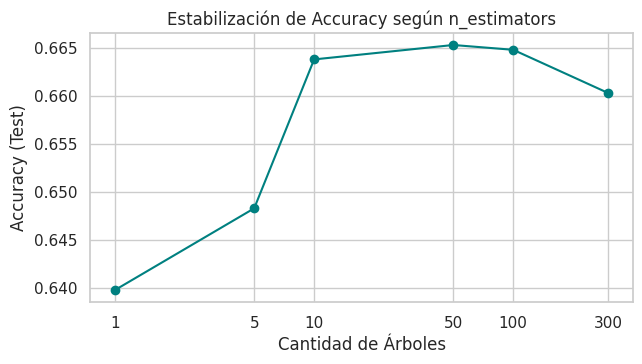

              precision    recall  f1-score   support

  Normal (0)       0.69      0.74      0.72      1140
  Riesgo (1)       0.62      0.56      0.59       856

    accuracy                           0.66      1996
   macro avg       0.66      0.65      0.65      1996
weighted avg       0.66      0.66      0.66      1996



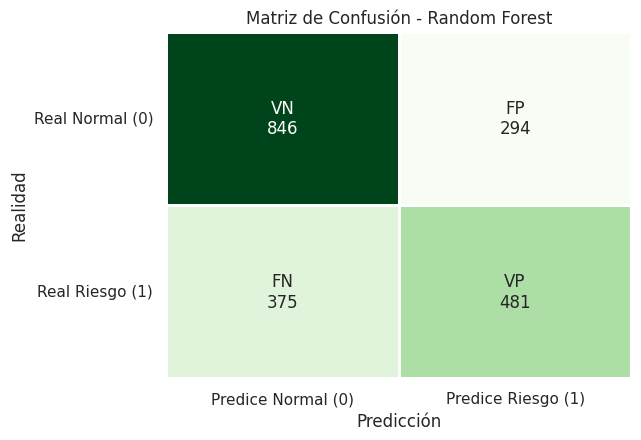

In [43]:
# 1. Curva de n_estimators
ns = [1, 5, 10, 50, 100, 300]
res = [(n, RandomForestClassifier(n_estimators=n, random_state=42).fit(X_train, y_train).score(X_test, y_test)) for n in ns]
df_curva = pd.DataFrame(res, columns=["n_arboles", "test_acc"])

plt.figure(figsize=(7, 3.5))
plt.plot(df_curva["n_arboles"], df_curva["test_acc"], marker="o", color="teal")
plt.xscale("log")
plt.xticks(ns, ns)
plt.title("Estabilización de Accuracy según n_estimators")
plt.xlabel("Cantidad de Árboles")
plt.ylabel("Accuracy (Test)")
plt.show()

# 2. Matriz de Confusión y Reporte
y_pred = modelo_rf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Normal (0)", "Riesgo (1)"]))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
nombres = np.array([["VN", "FP"], ["FN", "VP"]])
anot = np.array([[f"{nom}\n{val}" for nom, val in zip(fn, fv)] for fn, fv in zip(nombres, cm)])

plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=anot, fmt="", cmap="Greens", cbar=False, linewidths=1, linecolor="white")
plt.xticks([0.5, 1.5], ["Predice Normal (0)", "Predice Riesgo (1)"])
plt.yticks([0.5, 1.5], ["Real Normal (0)", "Real Riesgo (1)"], rotation=0)
plt.title("Matriz de Confusión - Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Realidad")
plt.show()

Bloque 4: Importancia de Variables y Prueba de Inferencia
Texto Markdown para Colab:

Markdown
## 4. Importancia de Variables e Inferencia de Prueba
Identificamos cuáles son los factores predictivos más influyentes en el modelo y realizamos una simulación de predicción en tiempo real.

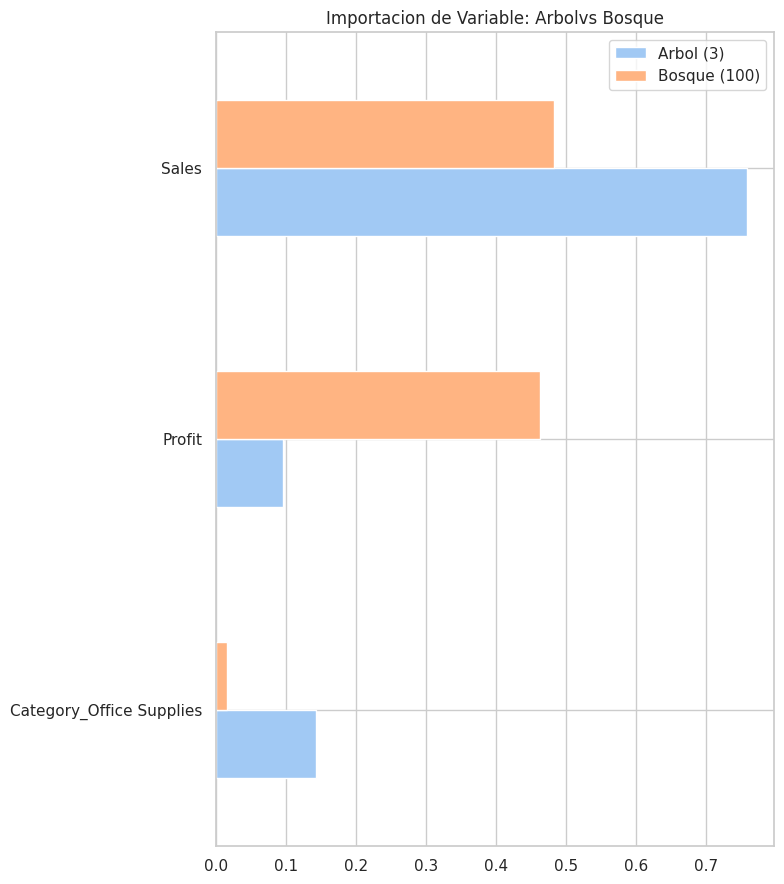

Resultado de la preduccion simulada: STOCKOUT NORMAL (0)


In [44]:
# Importancia de caracteristicas
imp_arbol = pd.Series(arbol.feature_importances_,  index=x.columns)
imp_bosque = pd.Series(modelo_rf.feature_importances_, index=x.columns)

df_imp = pd.DataFrame({'Arbol (3)': imp_arbol, 'Bosque (100)': imp_bosque}).sort_values('Bosque (100)')

fig, ax = plt.subplots(figsize=(8,9))
df_imp[df_imp['Bosque (100)'] > 0.01].plot(kind='barh', ax=ax)
plt.title('Importacion de Variable: Arbolvs Bosque')
plt.tight_layout()
plt.tight_layout()
plt.show()

# Inferenci sobre una muestra
muestra_simulada = x_test.iloc[[0]]
prediccion_demo = modelo_rf.predict(muestra_simulada)
resultado = 'RIESGO DE STOCKOUT (1)' if prediccion_demo[0] == 1 else 'STOCKOUT NORMAL (0)'

print(f'Resultado de la preduccion simulada: {resultado}')

# Escala unico de variables continuas (superstore)

In [45]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
import os

# Asegurar que df esté cargado en memoria
try:
    df_temp_check = df
except NameError:
    try:
        # Si df no existe, intentamos cargarlo usando la ruta de kagglehub previamente descargada
        df = pd.read_csv(os.path.join(path, "SampleSuperstore.csv"))
    except NameError:
        # En caso de que tampoco exista la variable 'path', descargamos el dataset nuevamente
        import kagglehub
        path = kagglehub.dataset_download("bravehart101/sample-supermarket-dataset")
        df = pd.read_csv(os.path.join(path, "SampleSuperstore.csv"))

# 1. Seleccionamos las columnas numéricas continuas
columnas_cluster = ['Sales', 'Profit']

# Extraemos la matriz con las variables a escalar
df_cluster = df[columnas_cluster].copy()

# Instanciamos y aplicamos el escalador
scaler = StandardScaler()
x_scaled = scaler.fit_transform(df_cluster)

# 2. Reconstruimos el DataFrame manteniendo nombres de columnas e índice
df_scaled = pd.DataFrame(x_scaled, columns=columnas_cluster, index=df_cluster.index)

# Visualizamos la muestra escalada (media ≈ 0, desviación estándar ≈ 1)
df_scaled.head()

,Sales,Profit
0,0.051005,0.056403
1,0.804552,0.814225
2,-0.345570,-0.093065
3,1.166330,-1.756144
4,-0.333148,-0.111641


In [46]:
from sklearn.cluster import KMeans

# K = 2
kmeans_k2 = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_k2.fit(x_scaled)

df_cluster["Grupo_K2"] = kmeans_k2.labels_
df_cluster.head()

,Sales,Profit,Grupo_K2
0,261.9600,41.9136,0
1,731.9400,219.5820,0
2,14.6200,6.8714,0
3,957.5775,-383.0310,0
4,22.3680,2.5164,0


# Visualizacion de clustere k-means (k=2) en superstore


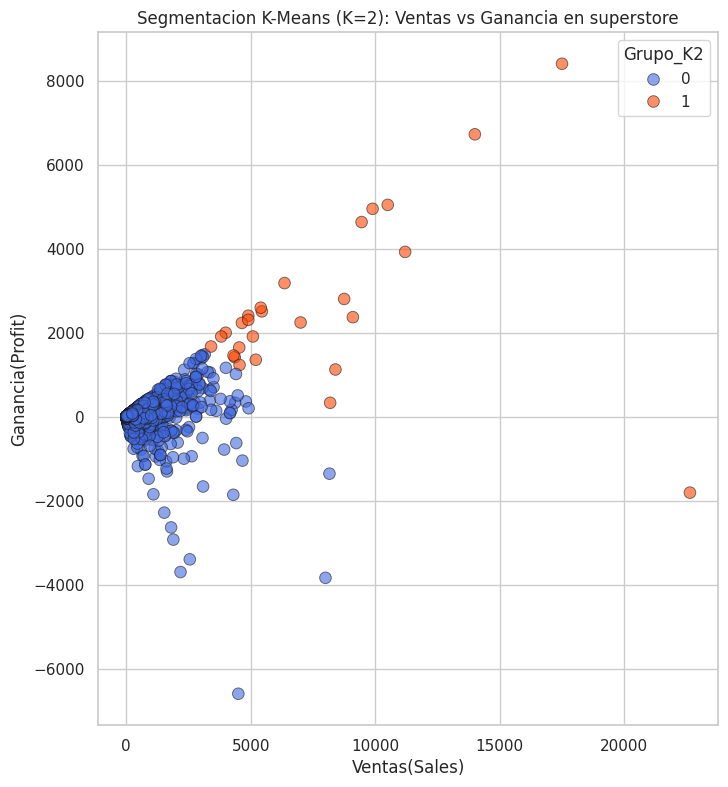

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,9))
sns.scatterplot(
    data=df_cluster,
    x='Sales', y='Profit',
    hue="Grupo_K2",
    palette=['royalblue', 'orangered'],
    alpha=0.6, s=70, edgecolor='k'
)

plt.xlabel("Ventas(Sales)")
plt.ylabel("Ganancia(Profit)")
plt.title("Segmentacion K-Means (K=2): Ventas vs Ganancia en superstore")
plt.show()